# 08 · LBD-Q-SAT Evaluation

## Colab setup

In [1]:
import os
import sys
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/UNIBO/Deep Learning/DL_3C")

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR.mkdir(parents=True, exist_ok=True)
    os.chdir(PROJECT_DIR)
    sys.path.insert(0, str(PROJECT_DIR))
else:
    PROJECT_DIR = Path.cwd()

IMAGES_DIR = PROJECT_DIR / "images"
MODELS_DIR = PROJECT_DIR / "models"
IMAGES_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

print("Working folder:", Path.cwd())
print("Files:", os.listdir())

Mounted at /content/drive
Working folder: /content/drive/MyDrive/UNIBO/Deep Learning/DL_3C
Files: ['images', 'models', 'train.pkl', 'val.pkl', 'test.pkl', 'test_large.pkl', '01_data_generation.ipynb', '__pycache__', 'neurosat.py', 'history.pkl', '02_model_and_training.ipynb', 'results.pkl', '03_evaluation.ipynb', 'cdcl.py', 'cdcl_check.pkl', '04_cdcl_solver_environment.ipynb', 'rl_data.pkl', 'baselines.pkl', '05_branching_baselines.ipynb', 'qnet.py', '06_graph_q_network.ipynb', 'dqn_history.pkl', '07_dqn_training.ipynb', '08_lbd_q_sat_evaluation.ipynb']


## Imports

In [2]:
import pickle
import random
import time

import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon

from cdcl import solve, vsids_literal
from qnet import QNetwork, q_literal

sns.set_theme(style="whitegrid", context="notebook")

## Settings

In [3]:
SEED = 42
DIM = 64
ROUNDS = 4
MAX_DECISIONS = 5000
GEN_VARS = 80
GEN_SIZE = 50
GLUE_LBD = 2

random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## Load data

In [4]:
with open("rl_data.pkl", "rb") as f:
    rl_data = pickle.load(f)

with open("baselines.pkl", "rb") as f:
    baselines = pickle.load(f)

with open("test_large.pkl", "rb") as f:
    large_test_data = pickle.load(f)

eval_sets = rl_data["eval"]
gen_data = large_test_data[GEN_VARS][:GEN_SIZE]

for name, data in eval_sets.items():
    print(f"{name:6s}: {len(data)} formulas")
print(f"{GEN_VARS:<6d}: {len(gen_data)} formulas (generalization)")

10–40 : 400 formulas
40    : 100 formulas
60    : 100 formulas
80    : 50 formulas (generalization)


## Load trained agents

In [5]:
agents = {}
for mode, name in [("flat", "Q flat"), ("lbd", "Q LBD")]:
    model = QNetwork(DIM, ROUNDS).to(device)
    model.load_state_dict(torch.load(MODELS_DIR / f"qnet_{mode}.pt", map_location=device))
    model.eval()
    agents[name] = model

print("Loaded:", list(agents.keys()))

Loaded: ['Q flat', 'Q LBD']


## Run function

In [6]:
def run(problem, choose):
    start = time.perf_counter()
    solver = solve(problem["n_vars"], problem["clauses"], choose, MAX_DECISIONS)
    elapsed = time.perf_counter() - start

    return {
        "n_vars": problem["n_vars"],
        "label": problem["label"],
        "finished": solver.result is not None,
        "correct": solver.result == bool(problem["label"]),
        "decisions": solver.decisions,
        "conflicts": solver.conflicts,
        "learned": len(solver.lbds),
        "mean_lbd": sum(solver.lbds) / len(solver.lbds) if solver.lbds else 0,
        "lbds": solver.lbds,
        "ms": elapsed * 1000,
    }

## Run agents on evaluation sets

In [7]:
rows = []

for set_name, data in eval_sets.items():
    for method, model in agents.items():
        choose = q_literal(model, device)
        for i, problem in enumerate(data):
            row = run(problem, choose)
            row.update({"set": set_name, "method": method, "formula": i})
            rows.append(row)
        print(f"Done {set_name} with {method}")

agent_results = pd.DataFrame(rows)

Done 10–40 with Q flat
Done 10–40 with Q LBD
Done 40 with Q flat
Done 40 with Q LBD
Done 60 with Q flat
Done 60 with Q LBD


## Baseline results

In [8]:
baseline_results = baselines["results"].rename(columns={"heuristic": "method"}).copy()
baseline_results["formula"] = baseline_results.groupby(["set", "method"]).cumcount()

print(baseline_results.groupby(["set", "method"]).size())

set    method
10–40  DLIS      400
       Random    400
       VSIDS     400
40     DLIS      100
       Random    100
       VSIDS     100
60     DLIS      100
       Random    100
       VSIDS     100
dtype: int64


## Generalization to larger formulas

In [9]:
gen_methods = {"VSIDS": vsids_literal}
for method, model in agents.items():
    gen_methods[method] = q_literal(model, device)

rows = []
for method, choose in gen_methods.items():
    for i, problem in enumerate(gen_data):
        row = run(problem, choose)
        row.update({"set": str(GEN_VARS), "method": method, "formula": i})
        rows.append(row)
    print(f"Done {GEN_VARS} with {method}")

gen_results = pd.DataFrame(rows)

Done 80 with VSIDS
Done 80 with Q flat
Done 80 with Q LBD


## Combine results

In [10]:
results = pd.concat([baseline_results, agent_results, gen_results], ignore_index=True)

SET_ORDER = list(eval_sets.keys()) + [str(GEN_VARS)]
METHOD_ORDER = ["VSIDS", "DLIS", "Random", "Q flat", "Q LBD"]

print("Rows:", len(results))
print(results.groupby(["set", "method"]).size().unstack())

Rows: 3150
method   DLIS  Q LBD  Q flat  Random  VSIDS
set                                        
10–40   400.0  400.0   400.0   400.0  400.0
40      100.0  100.0   100.0   100.0  100.0
60      100.0  100.0   100.0   100.0  100.0
80        NaN   50.0    50.0     NaN   50.0


## Correctness check

In [11]:
finished = results[results["finished"]]

print("Unfinished runs:")
print(results[~results["finished"]].groupby(["set", "method"]).size())
print()
print("Wrong finished answers:", (~finished["correct"]).sum())

Unfinished runs:
Series([], dtype: int64)

Wrong finished answers: 0


## Mean decisions

In [12]:
mean_decisions = results.pivot_table(index="set", columns="method", values="decisions", aggfunc="mean")
mean_decisions = mean_decisions.reindex(index=SET_ORDER, columns=METHOD_ORDER)
print(mean_decisions.round(1))

method  VSIDS  DLIS  Random  Q flat  Q LBD
set                                       
10–40     5.4   5.2     5.3     3.6    3.6
40        8.1   8.0     8.5     5.4    5.2
60       11.6  11.7    12.2     6.8    7.1
80       15.4   NaN     NaN     9.1    9.9


## Median decisions

In [13]:
median_decisions = results.pivot_table(index="set", columns="method", values="decisions", aggfunc="median")
median_decisions = median_decisions.reindex(index=SET_ORDER, columns=METHOD_ORDER)
print(median_decisions)

method  VSIDS  DLIS  Random  Q flat  Q LBD
set                                       
10–40     4.0   4.0     4.0     3.0    3.0
40        6.0   6.5     8.0     5.0    5.0
60       11.5  10.5    11.0     5.5    6.0
80       14.0   NaN     NaN     9.0    8.0


## Decisions relative to VSIDS

In [14]:
relative = median_decisions.div(median_decisions["VSIDS"], axis=0)
print(relative.round(2))

method  VSIDS  DLIS  Random  Q flat  Q LBD
set                                       
10–40     1.0  1.00    1.00    0.75   0.75
40        1.0  1.08    1.33    0.83   0.83
60        1.0  0.91    0.96    0.48   0.52
80        1.0   NaN     NaN    0.64   0.57


## SAT and UNSAT separately

In [15]:
by_label = results.pivot_table(index=["set", "label"], columns="method", values="decisions", aggfunc="median")
by_label = by_label.reindex(columns=METHOD_ORDER)
print(by_label)

method       VSIDS  DLIS  Random  Q flat  Q LBD
set   label                                    
10–40 0        3.0   2.0     3.0     1.0    1.0
      1        6.0   7.0     6.0     5.0    5.0
40    0        4.0   3.0     4.5     2.0    2.0
      1       10.0  11.5    10.5     7.5    8.0
60    0        5.0   4.5     5.5     3.0    3.0
      1       15.5  17.0    17.0    10.5   11.0
80    0        8.0   NaN     NaN     2.0    2.0
      1       19.0   NaN     NaN    14.0   14.0


## Learned clause quality

In [16]:
def clause_stats(group):
    lbds = [lbd for row in group["lbds"] for lbd in row]
    if not lbds:
        return pd.Series({"learned": 0, "mean_lbd": 0.0, "glue_share": 0.0})
    return pd.Series({
        "learned": len(lbds),
        "mean_lbd": sum(lbds) / len(lbds),
        "glue_share": sum(lbd <= GLUE_LBD for lbd in lbds) / len(lbds),
    })


quality = results.groupby(["set", "method"])[["lbds"]].apply(clause_stats)
print(quality.round(3))

              learned  mean_lbd  glue_share
set   method                               
10–40 DLIS      563.0     1.510       0.895
      Q LBD     610.0     1.339       0.956
      Q flat    620.0     1.327       0.963
      Random    876.0     1.491       0.912
      VSIDS     811.0     1.514       0.894
40    DLIS      191.0     1.607       0.880
      Q LBD     199.0     1.347       0.935
      Q flat    206.0     1.510       0.879
      Random    304.0     1.711       0.839
      VSIDS     274.0     1.748       0.832
60    DLIS      259.0     1.865       0.753
      Q LBD     252.0     1.595       0.885
      Q flat    228.0     1.482       0.917
      Random    405.0     1.802       0.802
      VSIDS     363.0     1.953       0.758
80    Q LBD     129.0     1.643       0.860
      Q flat    117.0     1.496       0.949
      VSIDS     201.0     2.020       0.736


## Decisions plot

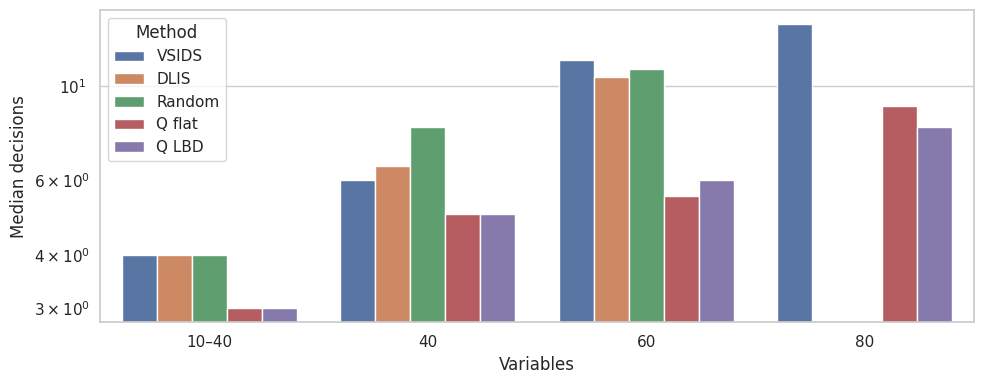

In [17]:
plt.figure(figsize=(10, 4))
ax = sns.barplot(data=results, x="set", y="decisions", hue="method", order=SET_ORDER, hue_order=METHOD_ORDER, estimator="median", errorbar=None)
ax.set_yscale("log")
ax.get_legend().set_title("Method")
plt.xlabel("Variables")
plt.ylabel("Median decisions")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "final_decisions.png", dpi=150)
plt.show()

## LBD distribution of the two agents

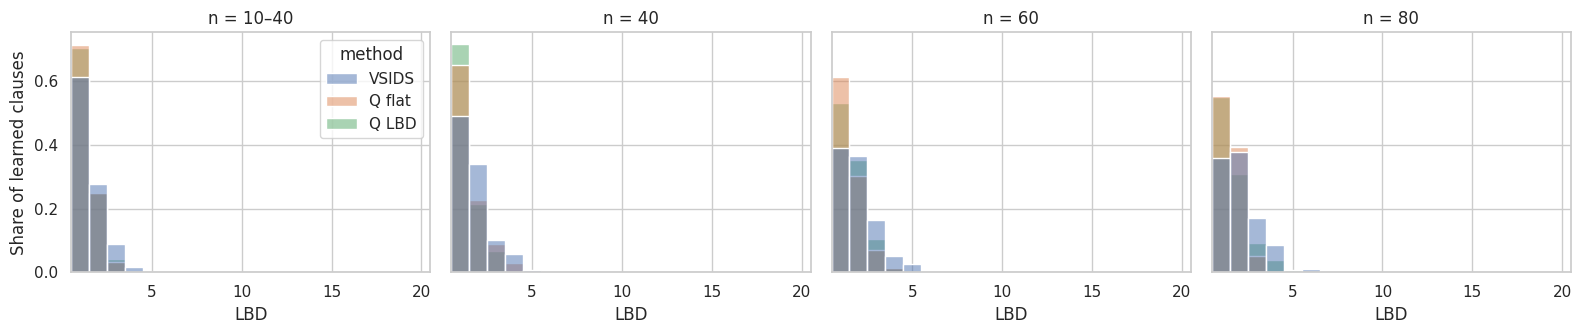

In [18]:
lbd_methods = ["VSIDS", "Q flat", "Q LBD"]

fig, axes = plt.subplots(1, len(SET_ORDER), figsize=(4 * len(SET_ORDER), 3.5), sharey=True)

for ax, set_name in zip(axes, SET_ORDER):
    subset = results[(results["set"] == set_name) & (results["method"].isin(lbd_methods))]
    lbd_df = subset[["method", "lbds"]].explode("lbds").dropna().reset_index(drop=True)
    lbd_df["lbds"] = lbd_df["lbds"].astype(int)
    if len(lbd_df):
        sns.histplot(data=lbd_df, x="lbds", hue="method", hue_order=lbd_methods, stat="density", common_norm=False, discrete=True, alpha=0.5, legend=ax is axes[0], ax=ax)
    ax.set_xlim(0.5, 20.5)
    ax.set_title(f"n = {set_name}")
    ax.set_xlabel("LBD")

axes[0].set_ylabel("Share of learned clauses")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "final_lbd_distribution.png", dpi=150)
plt.show()

## Flat vs LBD per formula

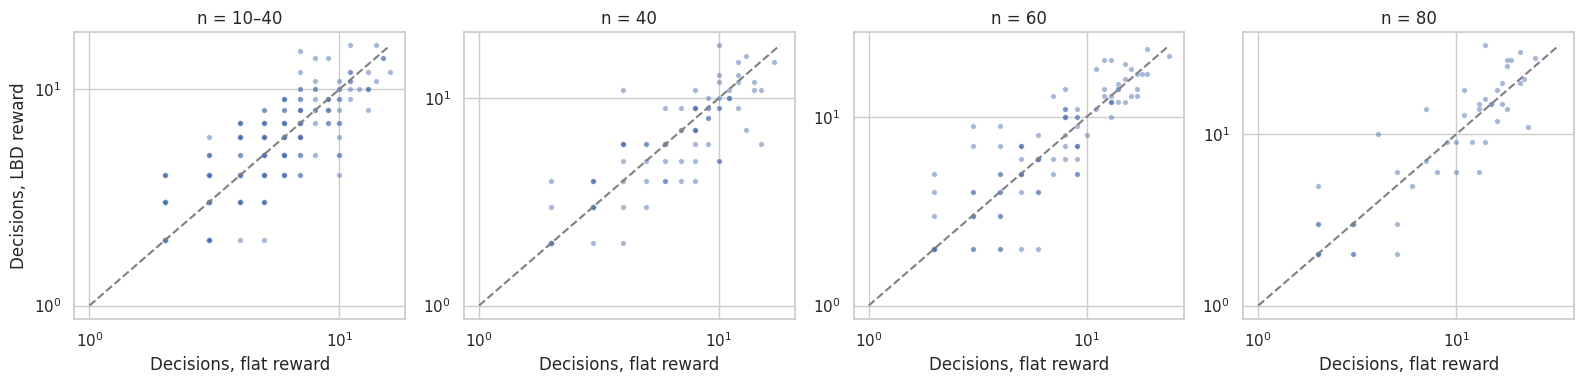

In [19]:
fig, axes = plt.subplots(1, len(SET_ORDER), figsize=(4 * len(SET_ORDER), 4))

for ax, set_name in zip(axes, SET_ORDER):
    flat = results[(results["set"] == set_name) & (results["method"] == "Q flat")].sort_values("formula")["decisions"].values
    lbd = results[(results["set"] == set_name) & (results["method"] == "Q LBD")].sort_values("formula")["decisions"].values
    sns.scatterplot(x=flat + 1, y=lbd + 1, s=15, alpha=0.5, ax=ax)
    top = max(flat.max(), lbd.max()) + 1
    ax.plot([1, top], [1, top], color="gray", linestyle="--")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"n = {set_name}")
    ax.set_xlabel("Decisions, flat reward")

axes[0].set_ylabel("Decisions, LBD reward")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "final_flat_vs_lbd.png", dpi=150)
plt.show()

## Win rates

In [20]:
def paired(set_name, method):
    subset = results[(results["set"] == set_name) & (results["method"] == method)]
    return subset.sort_values("formula")["decisions"].values


print(f"{'n':>6s} | {'comparison':>18s} | {'better':>6s} | {'worse':>6s} | {'tie':>6s}")
for set_name in SET_ORDER:
    lbd = paired(set_name, "Q LBD")
    for other in ["Q flat", "VSIDS"]:
        o = paired(set_name, other)
        print(f"{set_name:>6s} | {'Q LBD vs ' + other:>18s} | {(lbd < o).mean():6.2f} | {(lbd > o).mean():6.2f} | {(lbd == o).mean():6.2f}")

     n |         comparison | better |  worse |    tie
 10–40 |    Q LBD vs Q flat |   0.23 |   0.24 |   0.53
 10–40 |     Q LBD vs VSIDS |   0.61 |   0.16 |   0.23
    40 |    Q LBD vs Q flat |   0.34 |   0.27 |   0.39
    40 |     Q LBD vs VSIDS |   0.66 |   0.12 |   0.22
    60 |    Q LBD vs Q flat |   0.34 |   0.36 |   0.30
    60 |     Q LBD vs VSIDS |   0.82 |   0.09 |   0.09
    80 |    Q LBD vs Q flat |   0.34 |   0.38 |   0.28
    80 |     Q LBD vs VSIDS |   0.84 |   0.10 |   0.06


## Significance test

In [21]:
for set_name in SET_ORDER:
    flat = paired(set_name, "Q flat")
    lbd = paired(set_name, "Q LBD")
    if (flat != lbd).any():
        statistic, p_value = wilcoxon(flat, lbd)
        print(f"n={set_name:6s} | Wilcoxon p-value, flat vs LBD: {p_value:.4f}")
    else:
        print(f"n={set_name:6s} | identical decisions, no test")

n=10–40  | Wilcoxon p-value, flat vs LBD: 0.3951
n=40     | Wilcoxon p-value, flat vs LBD: 0.2957
n=60     | Wilcoxon p-value, flat vs LBD: 0.5123
n=80     | Wilcoxon p-value, flat vs LBD: 0.3814


## Solving time

In [22]:
mean_time = results.pivot_table(index="set", columns="method", values="ms", aggfunc="mean")
mean_time = mean_time.reindex(index=SET_ORDER, columns=METHOD_ORDER)
print(mean_time.round(1))

method  VSIDS  DLIS  Random  Q flat  Q LBD
set                                       
10–40     1.2   1.6     1.2    16.9   13.3
40        2.7   3.3     2.6    21.3   25.3
60        5.4   7.0     5.7    35.0   29.8
80        8.8   NaN     NaN    40.0   43.6


## Final summary

In [23]:
summary = pd.DataFrame({
    "VSIDS median decisions": median_decisions["VSIDS"],
    "Q flat median decisions": median_decisions["Q flat"],
    "Q LBD median decisions": median_decisions["Q LBD"],
    "Q flat mean LBD": [quality.loc[(s, "Q flat"), "mean_lbd"] for s in SET_ORDER],
    "Q LBD mean LBD": [quality.loc[(s, "Q LBD"), "mean_lbd"] for s in SET_ORDER],
}, index=SET_ORDER)

print(summary.round(2))

       VSIDS median decisions  Q flat median decisions  \
10–40                     4.0                      3.0   
40                        6.0                      5.0   
60                       11.5                      5.5   
80                       14.0                      9.0   

       Q LBD median decisions  Q flat mean LBD  Q LBD mean LBD  
10–40                     3.0             1.33            1.34  
40                        5.0             1.51            1.35  
60                        6.0             1.48            1.60  
80                        8.0             1.50            1.64  


## Save

In [24]:
with open("final_results.pkl", "wb") as f:
    pickle.dump({"results": results, "summary": summary, "quality": quality}, f)

print("Saved final_results.pkl and the final plots")

Saved final_results.pkl and the final plots
